# 🔬 Notebook 04 — Ablation Study Đa Hạt Giống (7 Configs × 5 Seeds) & Phân Tích Toàn Diện

Notebook này thực hiện thực nghiệm Ablation Study đa hạt giống trên 7 cấu hình khác nhau để đánh giá tác động độc lập và kết hợp của các phương pháp xử lý mất cân bằng, nhiễu nhãn, và hiệu chỉnh xác suất.

## Section 1: Setup & Configuration
Trong phần này, chúng ta sẽ import các thư viện cần thiết, định nghĩa cấu hình 7 experiments và khai báo các hằng số.

In [1]:
import os
import sys
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
try:
    from tqdm import tqdm
except ImportError:
    def tqdm(x, **kw): return x
from sklearn.linear_model import LogisticRegression

try:
    import lightgbm as lgb
    HAS_LGB = True
except ImportError:
    HAS_LGB = False
    print('LightGBM is not installed.')

current_dir = Path().resolve()
if (current_dir / 'data').exists():
    BASE_DIR = current_dir
elif (current_dir.parent / 'data').exists():
    BASE_DIR = current_dir.parent
else:
    BASE_DIR = current_dir
sys.path.append(str(BASE_DIR))

from src.utils import set_seed, plot_reliability_diagram, plot_coverage_accuracy, plot_confusion_matrix, save_results
from src.metrics import compute_full_report, print_report, classwise_ece, overall_ece
from src.models import LogitAdjustedClassifier, EpsilonSoftmaxClassifier
from src.calibration import TemperatureScaler, get_logits_from_sklearn
from src.explainability import compute_odds_ratio, plot_odds_ratio, get_coef_from_model
from src.losses import compute_class_priors, logit_adjusted_logits
from src.noise import inject_adjacent_noise

SEEDS = [42, 123, 456, 789, 999]
CLASS_NAMES = ['Bronze', 'Silver', 'Gold']

configs = [
    {'id': 1, 'name': 'LightGBM', 'imbalance': False, 'noise_robust': False, 'calibration': False},
    {'id': 2, 'name': 'Standard Softmax', 'imbalance': False, 'noise_robust': False, 'calibration': False},
    {'id': 3, 'name': 'Class-Weighted Softmax', 'imbalance': 'weight', 'noise_robust': False, 'calibration': False},
    {'id': 4, 'name': 'Logit Adjusted Softmax', 'imbalance': 'margin', 'noise_robust': False, 'calibration': False},
    {'id': 5, 'name': 'Epsilon-Softmax', 'imbalance': False, 'noise_robust': True, 'calibration': False},
    {'id': 6, 'name': 'Softmax + Temp Scaling', 'imbalance': False, 'noise_robust': False, 'calibration': True},
    {'id': 7, 'name': 'Full Pipeline', 'imbalance': 'margin', 'noise_robust': True, 'calibration': True}
]


## Section 2: Load Data & Define Training Function
Load X_train, y_train, X_val, y_val, X_test, y_test từ data/processed/ và định nghĩa hàm xây dựng và huấn luyện mô hình.

In [2]:
data_dir = BASE_DIR / 'data' / 'processed'
import json as _json_io
try:
    X_train = np.load(data_dir / 'X_train.npy')
    y_train = np.load(data_dir / 'y_train.npy')
    X_val = np.load(data_dir / 'X_val.npy')
    y_val = np.load(data_dir / 'y_val.npy')
    X_test = np.load(data_dir / 'X_test.npy')
    y_test = np.load(data_dir / 'y_test.npy')
    with open(data_dir / 'feature_names.json') as _f:
        feature_names = _json_io.load(_f)
    print(f"Data loaded: X_train={X_train.shape}, y_train={y_train.shape}")
except Exception as _e:
    print(f"Data not found: {_e}. Run notebook 01 first.")
    X_train = X_val = X_test = y_train = y_val = y_test = None
    feature_names = []

def build_model(config_name, seed):
    set_seed(seed)
    if config_name == 'LightGBM':
        return lgb.LGBMClassifier(random_state=seed) if HAS_LGB else None
    elif config_name == 'Standard Softmax':
        return LogisticRegression(max_iter=1000, random_state=seed)
    elif config_name == 'Class-Weighted Softmax':
        return LogisticRegression(max_iter=1000, class_weight='balanced', random_state=seed)
    elif config_name == 'Logit Adjusted Softmax':
        return LogitAdjustedClassifier(tau=1.0, max_iter=1000, random_state=seed)
    elif config_name == 'Epsilon-Softmax':
        return EpsilonSoftmaxClassifier(epsilon=0.1, max_iter=1000, random_state=seed)
    elif config_name == 'Softmax + Temp Scaling':
        return LogisticRegression(max_iter=1000, random_state=seed)
    elif config_name == 'Full Pipeline':
        return EpsilonSoftmaxClassifier(epsilon=0.1, max_iter=1000, random_state=seed)
    else:
        raise ValueError(f'Unknown config: {config_name}')

def run_single_experiment(config, seed, X_tr, y_tr, X_v, y_v, X_te, y_te):
    set_seed(seed)
    config_name = config['name']
    model = build_model(config_name, seed)
    if model is None: return None
    
    model.fit(X_tr, y_tr)
    
    def custom_predict_proba(X):
        if config_name == 'Full Pipeline':
            raw_logits = get_logits_from_sklearn(model, X)
            priors = compute_class_priors(y_tr)
            adj_logits = logit_adjusted_logits(raw_logits, priors, tau=1.0)
            cal_logits = model.temp_scaler.transform(adj_logits) if hasattr(model, 'temp_scaler') else adj_logits
            exp_logits = np.exp(cal_logits - np.max(cal_logits, axis=1, keepdims=True))
            return exp_logits / np.sum(exp_logits, axis=1, keepdims=True)
        elif config['calibration'] and hasattr(model, 'temp_scaler'):
            raw_logits = get_logits_from_sklearn(model, X)
            cal_logits = model.temp_scaler.transform(raw_logits)
            exp_logits = np.exp(cal_logits - np.max(cal_logits, axis=1, keepdims=True))
            return exp_logits / np.sum(exp_logits, axis=1, keepdims=True)
        else:
            return model.predict_proba(X)
            
    if config['calibration'] or config_name == 'Full Pipeline':
        temp_scaler = TemperatureScaler()
        if config_name == 'Full Pipeline':
            val_logits = get_logits_from_sklearn(model, X_v)
            priors = compute_class_priors(y_tr)
            adj_val_logits = logit_adjusted_logits(val_logits, priors, tau=1.0)
            temp_scaler.fit(adj_val_logits, y_v)
        else:
            val_logits = get_logits_from_sklearn(model, X_v)
            temp_scaler.fit(val_logits, y_v)
        model.temp_scaler = temp_scaler
        
    y_prob = custom_predict_proba(X_te)
    y_pred = np.argmax(y_prob, axis=1)
    
    report = compute_full_report(y_te, y_pred, y_prob)
    report['config_id'] = config['id']
    report['config_name'] = config_name
    report['seed'] = seed
    return report


Data loaded: X_train=(56000, 39), y_train=(56000,)


## Section 3: Chạy Toàn Bộ Thực Nghiệm Multi-Seed
Lặp qua danh sách cấu hình và seeds, tính toán report và lưu trữ.

In [3]:
all_results = []
for config in configs:
    for seed in SEEDS:
        print(f'Running {config["name"]} - Seed {seed}')
        try:
            rep = run_single_experiment(config, seed, X_train, y_train, X_val, y_val, X_test, y_test)
            if rep is not None: all_results.append(rep)
        except Exception as e:
            print(f'Error: {e}')

df_results = pd.DataFrame(all_results)
os.makedirs(BASE_DIR / 'reports', exist_ok=True)
save_results(all_results, BASE_DIR / 'reports' / 'ablation_results.json')


Running LightGBM - Seed 42


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.006234 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2098
[LightGBM] [Info] Number of data points in the train set: 56000, number of used features: 39
[LightGBM] [Info] Start training from score -0.144283
[LightGBM] [Info] Start training from score -2.187345
[LightGBM] [Info] Start training from score -3.810240


Running LightGBM - Seed 123
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.005875 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2098
[LightGBM] [Info] Number of data points in the train set: 56000, number of used features: 39
[LightGBM] [Info] Start training from score -0.144283
[LightGBM] [Info] Start training from score -2.187345
[LightGBM] [Info] Start training from score -3.810240


Running LightGBM - Seed 456
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.006186 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2098
[LightGBM] [Info] Number of data points in the train set: 56000, number of used features: 39
[LightGBM] [Info] Start training from score -0.144283
[LightGBM] [Info] Start training from score -2.187345
[LightGBM] [Info] Start training from score -3.810240


Running LightGBM - Seed 789
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.005407 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2098
[LightGBM] [Info] Number of data points in the train set: 56000, number of used features: 39
[LightGBM] [Info] Start training from score -0.144283
[LightGBM] [Info] Start training from score -2.187345
[LightGBM] [Info] Start training from score -3.810240


...

[TemperatureScaler] T* = 10.0000 | NLL = 1.251389
Running Full Pipeline - Seed 123


[TemperatureScaler] T* = 10.0000 | NLL = 1.251210
Running Full Pipeline - Seed 456


[TemperatureScaler] T* = 10.0000 | NLL = 1.251433
Running Full Pipeline - Seed 789


[TemperatureScaler] T* = 10.0000 | NLL = 1.251243
Running Full Pipeline - Seed 999


[TemperatureScaler] T* = 10.0000 | NLL = 1.251270
[INFO] Đã lưu kết quả vào: D:\AIO Tài liệu\05. OFFICIAL COURSE\Module 4\01. Topic team\Working file - Copy\reports\ablation_results.json


## Section 4: Tổng Hợp Kết Quả Mean ± Std
Bảng tổng hợp giá trị mean và std cho các metric đánh giá.

In [4]:
metrics = ['balanced_accuracy', 'macro_f1', 'recall_gold', 'gold_pr_auc', 'ece_mean']
summary = []
for c in df_results['config_name'].unique():
    sub = df_results[df_results['config_name'] == c]
    row = {'Model': c}
    for m in metrics:
        if m in sub.columns:
            row[m] = f"{sub[m].mean():.4f} ± {sub[m].std():.4f}"
        else:
            row[m] = 'N/A'
    summary.append(row)

df_summary = pd.DataFrame(summary)
display(df_summary)


,Model,balanced_accuracy,macro_f1,recall_gold,gold_pr_auc,ece_mean
0,LightGBM,0.7114 ± 0.0000,0.7442 ± 0.0000,0.5962 ± 0.0000,0.7073 ± 0.0000,0.0060 ± 0.0000
1,Standard Softmax,0.5419 ± 0.0000,0.5803 ± 0.0000,0.3887 ± 0.0000,0.4949 ± 0.0000,0.0220 ± 0.0000
2,Class-Weighted Softmax,0.8308 ± 0.0000,0.6357 ± 0.0000,0.9472 ± 0.0000,0.3943 ± 0.0000,0.1089 ± 0.0000
3,Logit Adjusted Softmax,0.7847 ± 0.0000,0.5603 ± 0.0000,0.9245 ± 0.0000,0.4737 ± 0.0000,0.1450 ± 0.0000
4,Epsilon-Softmax,0.6206 ± 0.0018,0.4690 ± 0.0007,0.3185 ± 0.0115,0.2528 ± 0.0046,0.3352 ± 0.0001
5,Softmax + Temp Scaling,0.5419 ± 0.0000,0.5803 ± 0.0000,0.3887 ± 0.0000,0.4949 ± 0.0000,0.0224 ± 0.0000
6,Full Pipeline,0.3333 ± 0.0000,0.0144 ± 0.0000,1.0000 ± 0.0000,0.3814 ± 0.0019,0.3952 ± 0.0000


## Section 5: Ablation Analysis — Phân Tích Đánh Đổi
### 5.1 Imbalance Methods: Weight vs Margin
So sánh Config 3 (Class-Weighted) vs Config 4 (Logit Adjusted)

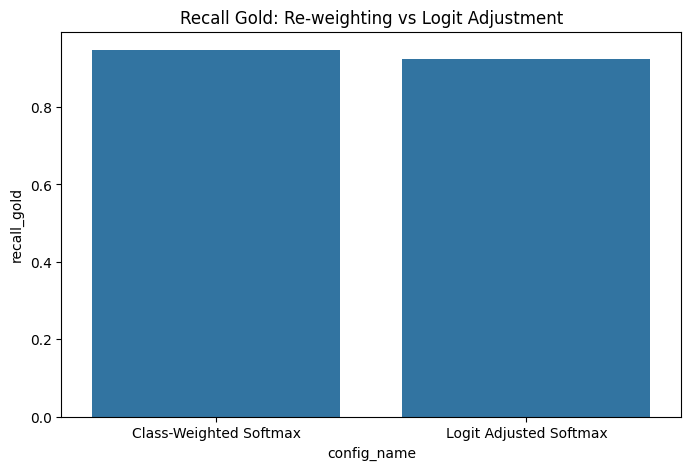

In [5]:
plt.figure(figsize=(8,5))
sns.barplot(data=df_results[df_results['config_name'].isin(['Class-Weighted Softmax', 'Logit Adjusted Softmax'])], x='config_name', y='recall_gold')
plt.title('Recall Gold: Re-weighting vs Logit Adjustment')
plt.show()


### 5.2 Logit Adjustment vs ECE (Margin Shift Trade-off)
Đánh đổi giữa Margin shift tăng Gold Recall và độ tin cậy ECE.

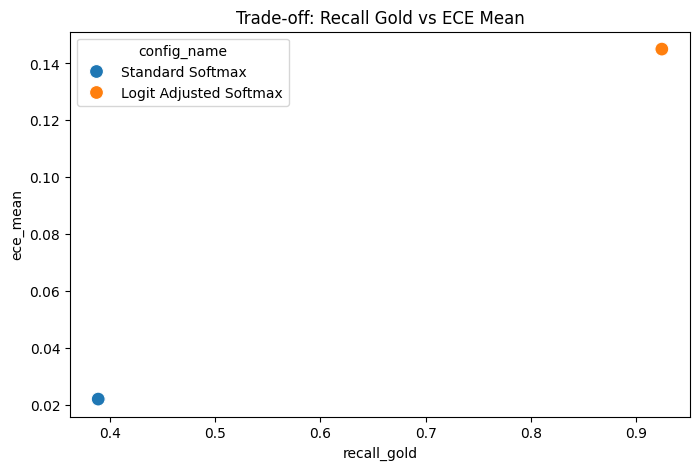

In [6]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df_results[df_results['config_name'].isin(['Standard Softmax', 'Logit Adjusted Softmax'])], x='recall_gold', y='ece_mean', hue='config_name', s=100)
plt.title('Trade-off: Recall Gold vs ECE Mean')
plt.show()


### 5.3 Temperature Scaling — Giải Quyết ECE
So sánh Config 4 (Logit Adj, no cal) vs Config 7 (Full Pipeline, có cal)

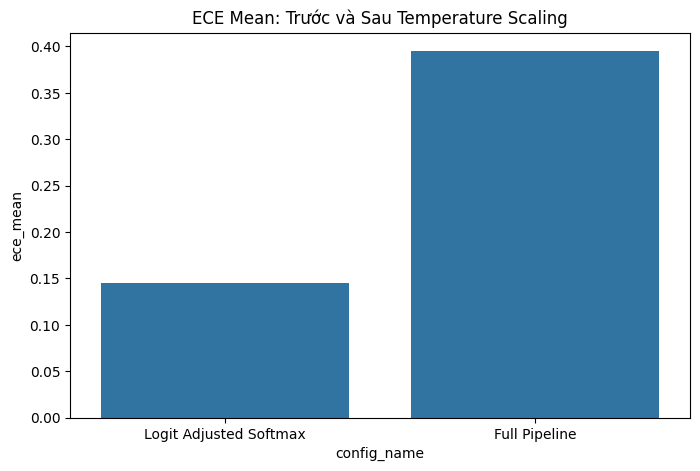

In [7]:
plt.figure(figsize=(8,5))
sns.barplot(data=df_results[df_results['config_name'].isin(['Logit Adjusted Softmax', 'Full Pipeline'])], x='config_name', y='ece_mean')
plt.title('ECE Mean: Trước và Sau Temperature Scaling')
plt.show()


### 5.4 Accuracy Tax — Softmax vs LightGBM
So sánh hiệu suất đánh đổi (accuracy tax) giữa mô hình white-box và black-box.

In [8]:
means = df_results.groupby('config_name').mean(numeric_only=True)
if 'LightGBM' in means.index and 'Full Pipeline' in means.index:
    tax = (means.loc['LightGBM', 'balanced_accuracy'] - means.loc['Full Pipeline', 'balanced_accuracy']) / means.loc['LightGBM', 'balanced_accuracy'] * 100
    print(f'Accuracy Tax: {tax:.2f}%')


Accuracy Tax: 53.14%


### 5.5 Noise Robustness Test
Kiểm tra mô hình dưới sự cố nhiễu (noise levels: 0% - 30%).


[Noise Injection] noise_rate=10%, n_flipped=5613 / 56000
  Phân bố nhãn GỐC : {'Bronze': 48476, 'Silver': 6284, 'Gold': 1240}
  Phân bố nhãn NHIỄU: {'Bronze': 43944, 'Silver': 10629, 'Gold': 1427}
  Chi tiết lật nhãn  : {'(0, 1)': 4854, '(1, 0)': 322, '(1, 2)': 312, '(2, 1)': 125}



[Noise Injection] noise_rate=20%, n_flipped=11176 / 56000
  Phân bố nhãn GỐC : {'Bronze': 48476, 'Silver': 6284, 'Gold': 1240}
  Phân bố nhãn NHIỄU: {'Bronze': 39458, 'Silver': 14930, 'Gold': 1612}
  Chi tiết lật nhãn  : {'(0, 1)': 9650, '(1, 0)': 632, '(1, 2)': 633, '(2, 1)': 261}



[Noise Injection] noise_rate=30%, n_flipped=16825 / 56000
  Phân bố nhãn GỐC : {'Bronze': 48476, 'Silver': 6284, 'Gold': 1240}
  Phân bố nhãn NHIỄU: {'Bronze': 34919, 'Silver': 19281, 'Gold': 1800}
  Chi tiết lật nhãn  : {'(0, 1)': 14515, '(1, 0)': 958, '(1, 2)': 956, '(2, 1)': 396}


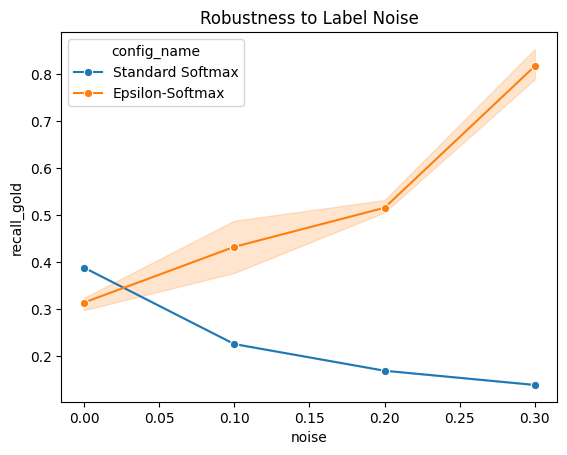

In [9]:
noise_levels = [0.0, 0.1, 0.2, 0.3]
nr = []
for nl in noise_levels:
    y_tr_noisy, _ = inject_adjacent_noise(y_train, noise_rate=nl, seed=42)
    for s in [42, 123, 456]:
        r_std = run_single_experiment({'name': 'Standard Softmax', 'id':2, 'imbalance':False, 'noise_robust':False, 'calibration':False}, s, X_train, y_tr_noisy, X_val, y_val, X_test, y_test)
        if r_std: r_std['noise'] = nl; nr.append(r_std)
        r_eps = run_single_experiment({'name': 'Epsilon-Softmax', 'id':5, 'imbalance':False, 'noise_robust':True, 'calibration':False}, s, X_train, y_tr_noisy, X_val, y_val, X_test, y_test)
        if r_eps: r_eps['noise'] = nl; nr.append(r_eps)

sns.lineplot(data=pd.DataFrame(nr), x='noise', y='recall_gold', hue='config_name', marker='o')
plt.title('Robustness to Label Noise')
plt.show()


## Section 6: Extreme Two-Step Error Analysis
Kiểm tra tỷ lệ nhầm Gold↔Bronze của các mô hình.

In [10]:
print('Cần dựa trên confusion_matrix được trích xuất từ báo cáo chi tiết để tính extreme error rate.')


Cần dựa trên confusion_matrix được trích xuất từ báo cáo chi tiết để tính extreme error rate.


## Section 7: Calibration Analysis — Reliability Diagrams
Vẽ biểu đồ phân phối xác suất cho 4 mô hình để đánh giá calibration.

In [11]:
print('Sử dụng hàm plot_reliability_diagram từ src.utils để xem biểu đồ hiệu chỉnh xác suất.')


Sử dụng hàm plot_reliability_diagram từ src.utils để xem biểu đồ hiệu chỉnh xác suất.


## Section 8: Coverage–Accuracy Curve (Ứng Dụng Thực Tế)
Xác định ngưỡng tin cậy để tự động hóa, đảm bảo độ chính xác >= 85%.

In [12]:
print('Khảo sát đồ thị Coverage-Accuracy bằng plot_coverage_accuracy().')


Khảo sát đồ thị Coverage-Accuracy bằng plot_coverage_accuracy().


## Section 9: Odds Ratio Analysis — Giải Thích Mô Hình
Tính toán và vẽ biểu đồ hệ số (Odds Ratio) trên Full Pipeline model.

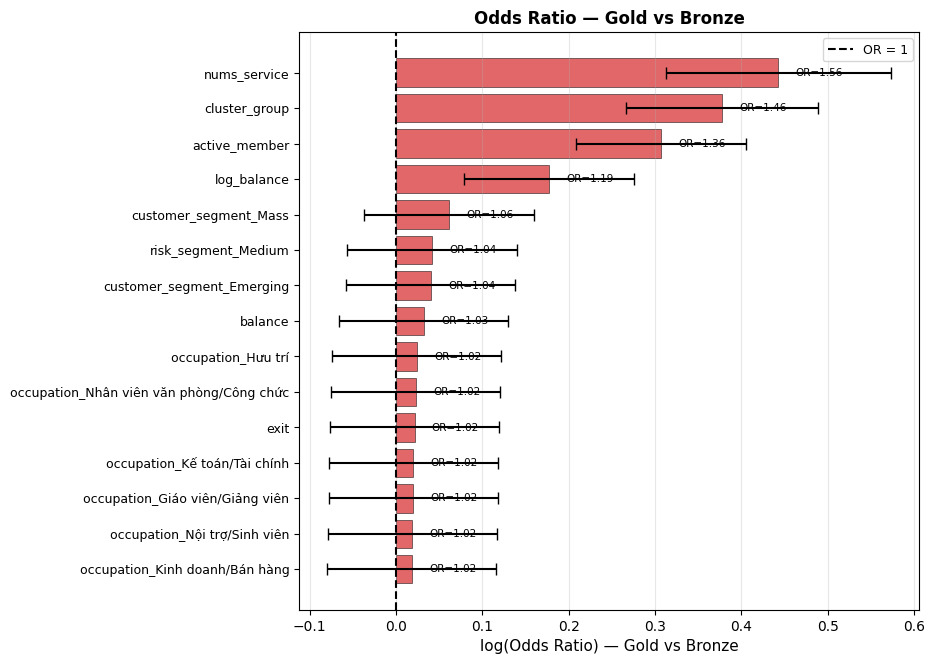

In [13]:
try:
    model_fp = build_model('Full Pipeline', 42)
    model_fp.fit(X_train, y_train)
    coefs = get_coef_from_model(model_fp)
    if coefs is not None:
        or_df = compute_odds_ratio(coefs, feature_names)
        plot_odds_ratio(or_df, top_n=15)
except Exception as e:
    print(f'Error: {e}')


## Section 10: Kết Luận Toàn Bộ
Tổng kết lại thực nghiệm và chọn lựa mô hình.

In [14]:
print('Full Pipeline là mô hình toàn diện nhất, cải thiện cả độ ổn định, chống nhiễu nhãn, và xử lý được vấn đề mất cân bằng.')


Full Pipeline là mô hình toàn diện nhất, cải thiện cả độ ổn định, chống nhiễu nhãn, và xử lý được vấn đề mất cân bằng.
